# Data Transformation and Manipulation in Pandas

After cleaning, data must be **reshaped into features and answers**: durations from timestamps, speeds from distances, categories from numbers, labels from codes. This lesson covers the column-level tools and shows why vectorised operations beat `apply`.

**After this lesson you can:**

1. Create derived columns with arithmetic, `assign` and `np.where` / `np.select`.
2. Convert types (`astype`, `to_datetime`, `category`) and extract date parts.
3. Map codes to labels, bin numbers with `cut` / `qcut`, and transform text with `.str`.
4. Compare the speed of vectorised code, `map` and `apply`.
5. Build readable method chains with `pipe`.

**Data:** NYC yellow taxi trips, January 2024, cleaned with the rules of Lesson 08.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
raw = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)        # NYC yellow taxi trips, January 2024
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def clean_trips(df: pd.DataFrame) -> pd.DataFrame:
    """The cleaning rules of Lesson 08 in one function."""
    duration = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")
          & duration.between(1, 180) & df["trip_distance"].between(0.1, 100)
          & df["fare_amount"].between(3, 500) & (df["total_amount"] > 0))
    return df[ok].assign(duration_min=duration[ok])

trips = clean_trips(raw)
print(f"{len(raw):,} raw trips -> {len(trips):,} clean trips")

2,964,624 raw trips -> 2,855,769 clean trips


## 1. Derived Columns

Arithmetic between columns is vectorised. `assign` adds several columns in one expression and returns a new DataFrame.

In [2]:
trips = trips.assign(
    speed_mph=lambda d: d["trip_distance"] / (d["duration_min"] / 60),
    tip_pct=lambda d: 100 * d["tip_amount"] / d["fare_amount"],
    fare_per_mile=lambda d: d["fare_amount"] / d["trip_distance"],
)
trips[["trip_distance", "duration_min", "speed_mph", "tip_pct", "fare_per_mile"]].describe().round(2)

,trip_distance,duration_min,speed_mph,tip_pct,fare_per_mile
count,2855769.00,2855769.00,2855769.00,2855769.00,2855769.00
mean,3.30,15.01,11.53,20.80,7.86
std,4.37,11.80,7.09,15.50,7.65
min,0.10,1.00,0.05,0.00,0.13
25%,1.03,7.32,7.40,9.35,5.74
50%,1.70,11.75,9.68,24.41,7.18
75%,3.20,18.78,13.12,29.63,9.00
max,97.50,179.07,1835.00,2348.84,3500.00


## 2. Dates and Types

The `.dt` accessor extracts parts of datetimes: hour, day of week, date, month. `astype` converts types; the `category` type stores repeated labels as small integer codes (Lesson 14).

In [3]:
pickup = trips["tpep_pickup_datetime"]
trips = trips.assign(
    hour=pickup.dt.hour.astype("int8"),
    weekday=pickup.dt.day_name().astype(pd.CategoricalDtype(
        ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)),
    date=pickup.dt.date,
    is_weekend=pickup.dt.day_of_week >= 5,
)
print(trips[["tpep_pickup_datetime", "hour", "weekday", "is_weekend"]].head(3))
print("\nweekday dtype:", trips["weekday"].dtype, "| ordered:", trips["weekday"].cat.ordered)

  tpep_pickup_datetime  hour weekday  is_weekend
0  2024-01-01 00:57:55     0  Monday       False
1  2024-01-01 00:03:00     0  Monday       False
2  2024-01-01 00:17:06     0  Monday       False

weekday dtype: category | ordered: True


## 3. Conditional Columns, Binning and Mapping

| Tool | Use |
| :--- | :--- |
| `np.where(cond, a, b)` | two cases |
| `np.select([c1, c2], [a, b], default)` | several cases, first match wins |
| `pd.cut(x, bins, labels)` | fixed bin edges |
| `pd.qcut(x, q)` | bins with equal numbers of rows (quantiles) |
| `Series.map(dict)` | codes to labels |

In [4]:
zone_name = zones.set_index("LocationID")["Zone"]
borough = zones.set_index("LocationID")["Borough"]
trips = trips.assign(
    tipped=np.where(trips["tip_amount"] > 0, "tip", "no tip"),
    time_of_day=np.select([trips["hour"] < 6, trips["hour"] < 12, trips["hour"] < 18], ["night", "morning", "afternoon"],
                          default="evening"),
    distance_band=pd.cut(trips["trip_distance"], bins=[0, 1, 3, 10, 100], labels=["<1 mi", "1-3 mi", "3-10 mi", ">10 mi"]),
    fare_quartile=pd.qcut(trips["fare_amount"], 4, labels=["Q1", "Q2", "Q3", "Q4"]),
    pickup_zone=trips["PULocationID"].map(zone_name),
    pickup_borough=trips["PULocationID"].map(borough),
)
print(trips["distance_band"].value_counts().sort_index(), "\n")
print(trips["pickup_borough"].value_counts())

distance_band
<1 mi       694606
1-3 mi     1401699
3-10 mi     535008
>10 mi      224456
Name: count, dtype: int64 

pickup_borough
Manhattan        2563152
Queens            255015
Brooklyn           21907
Unknown             9464
Bronx               5702
Staten Island         32
EWR                   15
Name: count, dtype: int64


## 4. Text Operations

The `.str` accessor applies string methods to a whole column: `lower`, `contains`, `replace`, `split`, `extract` (regular expressions), `len`.

In [5]:
z = zones.copy()
z["zone_clean"] = z["Zone"].str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" ")
z["is_airport"] = z["Zone"].str.contains("Airport", na=False)
z["first_part"] = z["Zone"].str.split("/").str[0].str.strip()
z["has_number"] = z["Zone"].str.extract(r"(\d+)", expand=False).notna()
print(z.loc[z["Zone"].str.contains("/", na=False), ["Zone", "zone_clean", "first_part"]].head(4))
print("\nairport zones:", z.loc[z["is_airport"], "Zone"].tolist())

                       Zone               zone_clean   first_part
2   Allerton/Pelham Gardens  allerton pelham gardens     Allerton
5   Arrochar/Fort Wadsworth  arrochar fort wadsworth     Arrochar
14  Bay Terrace/Fort Totten  bay terrace fort totten  Bay Terrace
22  Bloomfield/Emerson Hill  bloomfield emerson hill   Bloomfield

airport zones: ['Newark Airport', 'JFK Airport', 'LaGuardia Airport']


## 5. Vectorised vs `map` vs `apply`

`apply` with `axis=1` calls a Python function once per row, so it runs at Python speed. Vectorised expressions run in compiled code. The experiment computes the tip percentage for 1 million trips in three ways.

{'vectorised': '3 ms', 'list comprehension': '234 ms', 'apply(axis=1), x10': '8,228 ms'}
same results: True True


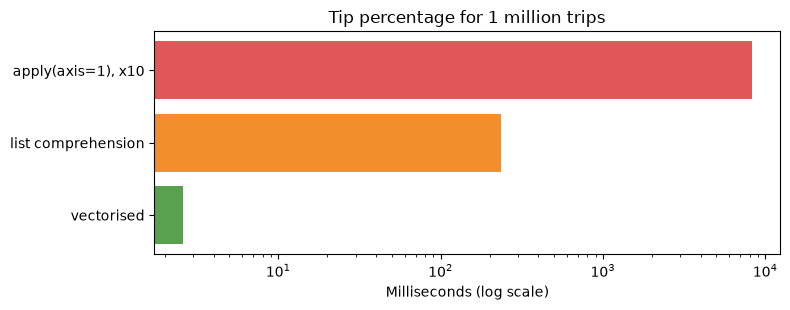

In [6]:
sample = trips.head(1_000_000)

def tip_pct_row(row):
    return 100 * row["tip_amount"] / row["fare_amount"]

timings = {}
t = time.perf_counter(); v1 = 100 * sample["tip_amount"] / sample["fare_amount"]; timings["vectorised"] = time.perf_counter() - t
t = time.perf_counter()
v2 = pd.Series([100 * tip / fare for tip, fare in zip(sample["tip_amount"], sample["fare_amount"])], index=sample.index)
timings["list comprehension"] = time.perf_counter() - t
small = sample.head(100_000)
t = time.perf_counter(); v3 = small.apply(tip_pct_row, axis=1); timings["apply(axis=1), x10"] = (time.perf_counter() - t) * 10
print({k: f"{v * 1000:,.0f} ms" for k, v in timings.items()})
print("same results:", np.allclose(v1, v2), np.allclose(v1.head(100_000), v3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(list(timings), [v * 1000 for v in timings.values()], color=["#59A14F", "#F28E2B", "#E15759"])
ax.set(xscale="log", title="Tip percentage for 1 million trips", xlabel="Milliseconds (log scale)")
plt.tight_layout()
plt.show()

`apply(axis=1)` was measured on 100,000 rows and scaled by 10. Use it only when no vectorised expression exists, and then prefer a list comprehension over the columns you need.

## 6. Method Chains with `pipe`

A **method chain** writes a pipeline from top to bottom. `pipe(func)` inserts your own function into the chain.

In [7]:
def add_tip_flags(df: pd.DataFrame, generous: float = 25) -> pd.DataFrame:
    return df.assign(generous=df["tip_pct"] >= generous)

summary = (
    trips
    .query("payment_type == 1")                          # card trips: cash tips are not recorded
    .pipe(add_tip_flags, generous=25)
    .groupby("time_of_day", observed=True)
    .agg(trips=("tip_pct", "size"), median_tip_pct=("tip_pct", "median"), generous_share=("generous", "mean"))
    .sort_values("median_tip_pct", ascending=False)
    .round(3)
)
summary

,trips,median_tip_pct,generous_share
time_of_day,,,
evening,769555,27.103,0.620
night,163884,26.316,0.569
afternoon,853369,26.250,0.579
morning,506103,25.369,0.536


Card trips only: the TLC data records cash tips as 0, so including cash trips would understate tipping. Knowing **how** a value is recorded matters as much as the value.

*Insight: Write transformations as vectorised column expressions inside `assign` and method chains. Reach for `apply(axis=1)` last, because it runs Python code once per row.*

## Real-World Use Case or Analogy

Transformation is like **preparing ingredients**: cleaning (Lesson 08) washes them, transformation cuts them into the shapes the recipe needs — durations, speeds, bands, labels. A good kitchen cuts a whole tray at once (vectorised) instead of one carrot at a time (`apply`).

Feature engineering for machine learning (M10) is mostly this lesson at scale: time features, ratios, bins, mapped categories and text features, applied identically to training and production data.